# Tugas Praktikum 3: Tugas_Ensemble.
**Nama:** Catherine Aprilia Harlina  
**NRP:** 5054251012  
**Mata Kuliah:** Data Mining / Rekayasa Kecerdasan Artifisial (ITS)

# tugas praktikum 3 - ensemble method & class imbalance

1. unduh dan import dataset
unduh creditcard.csv lalu impor menggunakan pandas, kemudian tampilkan head, shape, dan info

In [9]:
!pip install imbalanced-learn

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, f1_score, roc_curve, accuracy_score
from imblearn.over_sampling import SMOTE

df = pd.read_csv('creditcard.csv')
display(df.head())
print(df.shape)
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


(284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     

2. praproses data
identifikasi distribusi kelas pada atribut class (jumlah & persentase) lalu visualisasikan, bagi data 80:20 pakai stratify=y, dan terapkan smote khusus data latih

jumlah kelas:
 Class
0    284315
1       492
Name: count, dtype: int64

persentase kelas:
 Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


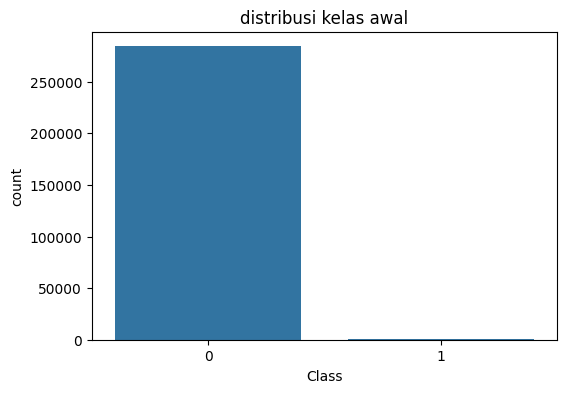

distribusi setelah smote pada data latih:
Class
0    227451
1    227451
Name: count, dtype: int64


In [11]:
class_counts = df['Class'].value_counts()
class_percentages = df['Class'].value_counts(normalize=True) * 100

print("jumlah kelas:\n", class_counts)
print("\npersentase kelas:\n", class_percentages)

plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('distribusi kelas awal')
plt.show()

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("distribusi setelah smote pada data latih:")
print(pd.Series(y_train_resampled).value_counts())

3. membangun model klasifikasi
menggunakan ensemble method random forest, bandingkan model tanpa dan dengan penanganan class imbalance (smote)

In [12]:
rf_normal = RandomForestClassifier(random_state=42, n_estimators=50)
rf_normal.fit(X_train, y_train)
y_pred_normal = rf_normal.predict(X_test)

print("laporan tanpa penanganan:")
print(classification_report(y_test, y_pred_normal))

rf_smote = RandomForestClassifier(random_state=42, n_estimators=50)
rf_smote.fit(X_train_resampled, y_train_resampled)
y_pred_smote = rf_smote.predict(X_test)

print("laporan dengan smote:")
print(classification_report(y_test, y_pred_smote))

laporan tanpa penanganan:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962

laporan dengan smote:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.91      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



4. evaluasi model
hitung precision, recall, f1-score, auc-roc, confusion matrix, serta penjelasan mengapa accuracy saja tidak cukup untuk dataset imbalanced ini

confusion matrix:
[[56847    17]
 [   17    81]]
accuracy: 0.9994
precision: 0.8265
recall: 0.8265
f1 score: 0.8265
auc-roc: 0.9608


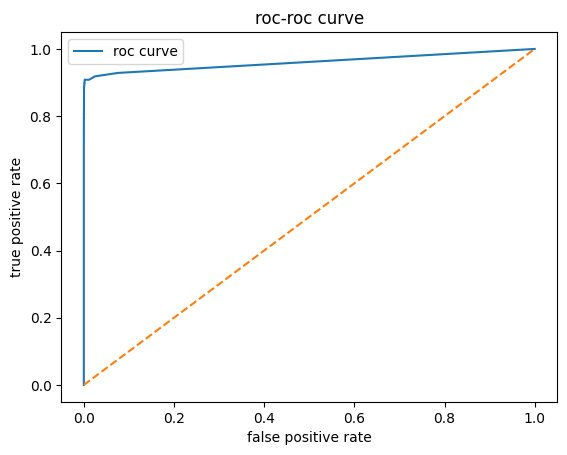

In [13]:
y_prob_smote = rf_smote.predict_proba(X_test)[:, 1]

print("confusion matrix:")
print(confusion_matrix(y_test, y_pred_smote))
print(f"accuracy: {accuracy_score(y_test, y_pred_smote):.4f}")
print(f"precision: {precision_score(y_test, y_pred_smote):.4f}")
print(f"recall: {recall_score(y_test, y_pred_smote):.4f}")
print(f"f1 score: {f1_score(y_test, y_pred_smote):.4f}")
print(f"auc-roc: {roc_auc_score(y_test, y_prob_smote):.4f}")

fpr, tpr, _ = roc_curve(y_test, y_prob_smote)
plt.plot(fpr, tpr, label='roc curve')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('roc-roc curve')
plt.legend()
plt.show()

kenapa accuracy saja tidak cukup? karena dataset fraud transaksi kartu kredit sangat imbalanced (mayoritas normal). kalau model cuma asal tebak semua jadi kelas 0 (normal), akurasinya bisa tetep tinggi di atas 99%, tapi gagal total mendeteksi transaksi penipuan (fraud) di kelas minoritas. makanya kita butuh metrics kaya precision, recall, f1-score, dan auc-roc.

Jumlah per kelas:
 Class
0    284315
1       492
Name: count, dtype: int64


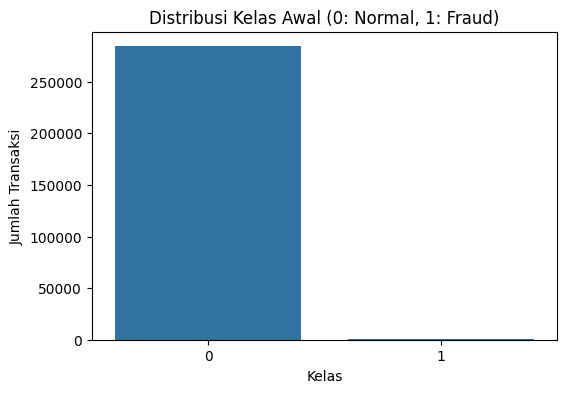

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('creditcard.csv')

# Hitung jumlah & persentase kelas
class_counts = df['Class'].value_counts()
print("Jumlah per kelas:\n", class_counts)

# Visualisasi grafik countplot
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df)
plt.title('Distribusi Kelas Awal (0: Normal, 1: Fraud)')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Transaksi')
plt.show() 